# O Perceptron
- https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Perceptron.html
- É um modelo **linear** para **classificação binária**
    - Só é possível fazer a separação se os dados forem **linearmente separáveis**
- O seu **aprendizado** é feito através do cálculo dos **pesos** e **vieses**


- Seu funcionamento é baseado no funcionamento do neurônio humano:
<img src="https://drive.google.com/uc?id=1CM4TqqEYyl81gVYYeIaSgA9Fb6lkd0vE" style='width: 1000px;' />



- Foi proposto em 1943 por McCulloch e Pitts e implementado pela primeira vez em 1958 por Frank Rosenblatt e segundo o The New York Times:
    -  **o perceptron é "o embrião de um computador eletrônico que [a Marinha] espera que seja capaz de andar, falar, ver, escrever, reproduzir-se e ter consciência de sua existência"**
- Devido a sua limitação de prever padrões simples como o OU exclusivo (XOR), ficou um tempo "congelado" mas foi retomado fortemente com o avanço do **Deep Learning**

In [52]:
#importando as bibliotecas
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

Link de acesso do dataset utilizado: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html#sklearn.datasets.load_iris

In [53]:
#importando o dataset iris
from sklearn.datasets import load_iris

In [55]:
#Determinando x e y
X_iris, y_iris = load_iris(return_X_y=True, as_frame=True)

In [57]:
#Vizualizando as 3 primeiras linhas do dataset
X_iris.head(3)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2


In [58]:
#Selecionando apenas as colunas de petala e o target 0 e 1 

x = X_iris.loc[y_iris.isin([0,1]), ['petal length (cm)', 'petal width (cm)']]
y = y_iris[y_iris.isin([0,1])]


In [59]:
#Verificando o valor de y
y.value_counts()

target
0    50
1    50
Name: count, dtype: int64

<function matplotlib.pyplot.show(close=None, block=None)>

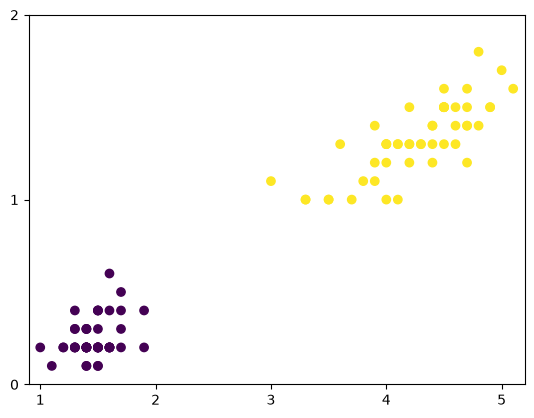

In [61]:
#Observando graficamente os dados
fig, ax = plt.subplots()

ax.scatter(X.iloc[:, 0], X.iloc[:, 1], c=Y)

ax.set(xlim=(0.9, 5.2), xticks=[1, 2, 3, 4, 5], ylim=(0,2), yticks=[0,1,2])
plt.show

Perceptron

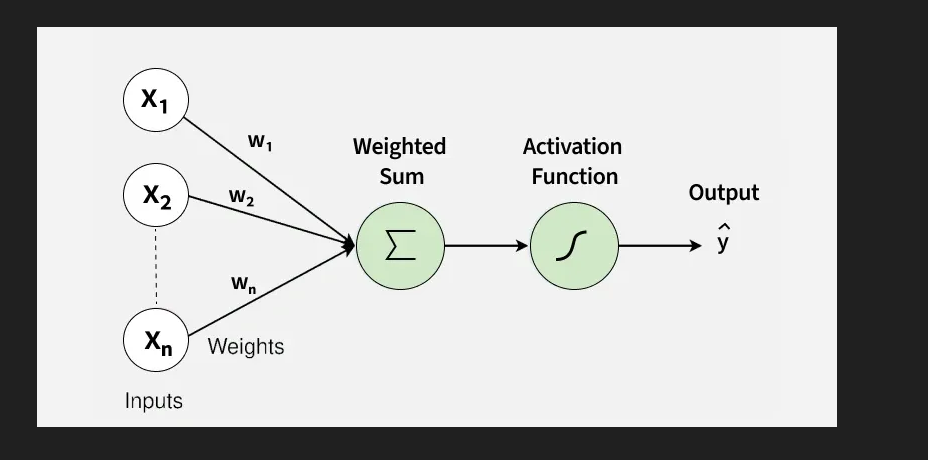

In [62]:
#Separando em treino e teste
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.33, random_state=42)

In [64]:
#Importando perceptron
from sklearn.linear_model import Perceptron

In [65]:
#Criando o classificador
clf = Perceptron(tol=1e-3, random_state=0, eta0=0.1)

In [66]:
#fit dos dados  t
clf = clf.fit(X_train, y_train)

In [67]:
#previsão teste
y_pred= clf.predict(X_test)


In [68]:
#Importando a matriz de confusão
from sklearn.metrics import confusion_matrix

In [69]:
#Avaliando modelo
confusion_matrix(y_test, y_pred)

array([[19,  0],
       [ 0, 14]])

Entendendo o que o perceptron fez!  

In [70]:
X_train.head(3)

,petal length (cm),petal width (cm)
28,1.4,0.2
93,3.3,1.0
5,1.7,0.4


In [71]:
y_train[:3] 

28    0
93    1
5     0
Name: target, dtype: int64

In [72]:
#verificando coef
clf.coef_

array([[0.08, 0.08]])

In [73]:
# E o intercept
clf.intercept_

array([-0.2])

In [74]:
# Podemos escrever w1, w2 e 20
w1 = round(clf.coef_[0][0], 2)
w2 = round(clf.coef_[0][1], 2)
w0 = clf.intercept_[0]
print(w1, w2, w0)

0.08 0.08 -0.2


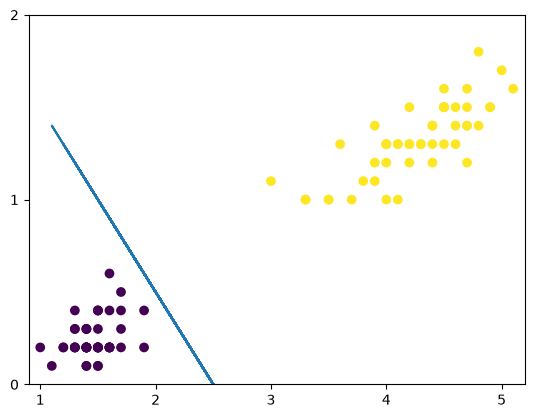

In [77]:
#Adcionando a linha de decisão ao gráfico
fig, ax = plt.subplots()

ax.scatter(X_train.iloc[:, 0], X_train.iloc[:,1],c=y_train)
ax.plot(X_train.iloc[:, 0], (-w1*X_train.iloc[:, 0]-w0)/w2)
ax.scatter(X_test.iloc[:, 0], X_test.iloc[:, 1], c=y_test)

ax.set(xlim=(0.9, 5.2), xticks=[1, 2, 3, 4, 5], 
       ylim=(0,2), yticks=[0,1,2])

plt.show()

Separando as duas classes

In [78]:
#Considerando as classes 1 e 2 
X = X_iris.loc[y_iris.isin([1,2]), ['petal length (cm)', 'petal width (cm)']]
y = y_iris[y_iris.isin([1,2])]

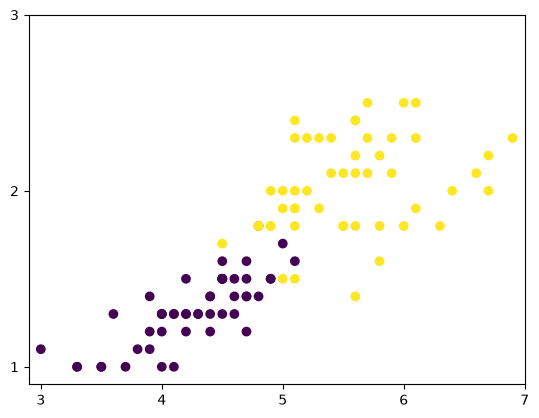

In [79]:
#Obeservando graficamente os dados
fig, ax = plt.subplots()
ax.scatter(X.iloc[:, 0], X.iloc[:, 1], c=y)

ax.set(xlim=(2.9, 7), xticks=[3, 4, 5, 6, 7],
       ylim=(0.9,3), yticks=[1,2,3])
plt.show()

In [80]:
#Separando dados de treino e teste
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

In [81]:
# Criando o classificador
clf = Perceptron(tol=1e-3, random_state=0, eta0=0.1)

In [82]:
#Fazendo fit com os dados
clf= clf.fit(X_train, y_train)

In [83]:
# Fazendo a previsão
y_pred = clf.predict(X_test)

In [84]:
# Avaliando modelo
confusion_matrix(y_test, y_pred)   

array([[19,  0],
       [ 2, 12]])

In [85]:
#Parte do w1 w2 e w0
w1 = round(clf.coef_[0][0], 2)
w2 = round(clf.coef_[0][1], 2)
w0 = clf.intercept_[0]
print(w1, w2, w0)

-0.24 3.07 -3.800000000000002


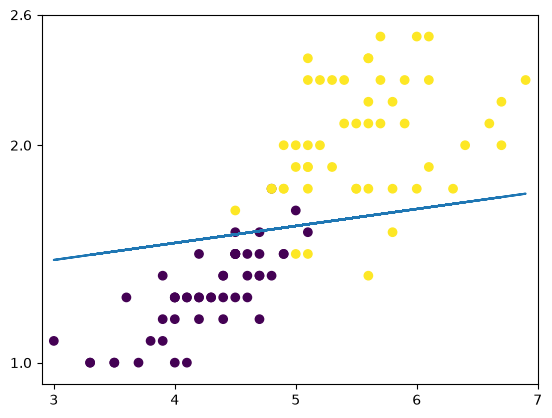

In [88]:
# Adcionando essa reta no grafico
fig, ax = plt.subplots()

ax.scatter(X_train.iloc[:, 0], X_train.iloc[:,1],c=y_train)
ax.plot(X_train.iloc[:, 0], (-w1*X_train.iloc[:,0]-w0)/w2)
ax.scatter(X_test.iloc[:, 0],X_test.iloc[:, 1],c=y_test)

ax.set(xlim=(2.9, 7), xticks=[3, 4, 5, 6, 7],
       ylim=(0.9,2.6), yticks=[1,2,2.6])

plt.show()

O perceptron só consegue separar os dados linearmente separaveis

ANALISANDO O PROBLEMA DO OR E DO XOR

In [89]:
#Vamos considerar inicialmente os dados a baixo
dados = pd.DataFrame({'x1':[0,0,1,1],
                       'x2':[0,1,0,1],
                         'y':[0,1,1,0]})

In [90]:
#Visualizando a base
dados

,x1,x2,y
0,0,0,0
1,0,1,1
2,1,0,1
3,1,1,0


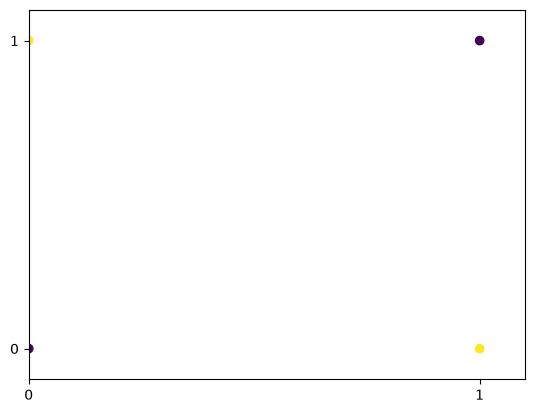

In [92]:
# E observando graficamente
fig, ax = plt.subplots()

ax.scatter(dados.x1,dados.x2,c=dados.y)

ax.set(xlim=[0.1,1.1], xticks=[0,1],
    ylim=[-0.1,1.1], yticks=[0,1])
plt.show()


In [93]:
# criando classificador 
clf = Perceptron(tol=1e-3, random_state=0, eta0=0.1)

In [94]:
#selecionando x e y
X = dados[['x1','x2']]
y = dados['y']

In [95]:
# fazendo o fit com os dados
clf= clf.fit(X, y)

In [96]:
# fazendo a previsão
y_pred = clf.predict(X)
y_pred

array([0, 0, 0, 0])

In [97]:
# Avaliando modelo
confusion_matrix(y, y_pred)

array([[2, 0],
       [2, 0]])

In [98]:
# verificando coef
clf.coef_

array([[0., 0.]])

In [99]:
#verificando intercept
clf.intercept_

array([0.])

In [100]:
#Podemos escrever w1,w2 e w0 como 
w1 = round(clf.coef_[0][0], 2)
w2 = round(clf.coef_[0][1], 2)  
w0 = clf.intercept_[0]
print(w1, w2, w0)

0.0 0.0 0.0


C:\Users\Carlos\AppData\Local\Temp\ipykernel_63348\2124396916.py:9: RuntimeWarning: invalid value encountered in divide
  y_perc = (-w1*x_perc-w0)/w2


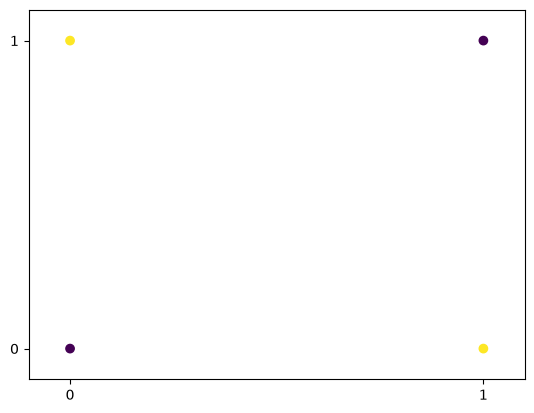

In [102]:
# Vizualizando esse resultado graficamente

fig, ax = plt.subplots()

#Criando um array de x
x_perc = np.linspace(-0.1, 1, 100)

#Agora calculando o y
y_perc = (-w1*x_perc-w0)/w2

ax.scatter(dados.x1,dados.x2,c=dados.y)
ax.plot(x_perc, y_perc, 'r')

ax.set(xlim=[-0.1, 1.1], xticks=[0,1],
    ylim=[-0.1, 1.1], yticks=[0,1])

plt.show()